In [1]:
# ============================================================
# Outcome III — Planetary-system architecture
# P0: congelar muestra y variables
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

df_arch = pd.read_csv(
    "../data_processed/05_sistemas_planetarios_enriquecido.csv"
)

df_arch.shape

(615, 23)

In [2]:
# ============================================================
# P0 — Muestra arquitectónica congelada
# ============================================================

sample_architecture = df_arch[
    df_arch["hostname"].notna() &
    df_arch["N_planetas"].notna() &
    df_arch["median_period_ratio"].notna() &
    df_arch["gapped"].notna() &
    df_arch["median_radius"].notna() &
    df_arch["st_mass"].notna() &
    df_arch["st_met"].notna()
].copy()

sample_architecture["gapped"] = sample_architecture["gapped"].astype(int)

sample_architecture.to_csv(
    "../data_processed/sample_outcomeIII_architecture.csv",
    index=False
)

print("N sistemas finales:", len(sample_architecture))
print("N hosts únicos:", sample_architecture["hostname"].nunique())

N sistemas finales: 615
N hosts únicos: 615


In [3]:
# ============================================================
# Disponibilidad de variables arquitectónicas
# ============================================================

tabla_disponibilidad_arch = pd.DataFrame({
    "variable": variables_arch,
    "N_disponibles": [
        df_arch[v].notna().sum() if v in df_arch.columns else np.nan
        for v in variables_arch
    ],
    "N_faltantes": [
        df_arch[v].isna().sum() if v in df_arch.columns else np.nan
        for v in variables_arch
    ],
    "porcentaje_disponible": [
        100 * df_arch[v].notna().mean() if v in df_arch.columns else np.nan
        for v in variables_arch
    ]
}).round(2)

tabla_disponibilidad_arch.to_csv(
    "../tables/P0_outcomeIII_variable_availability.csv",
    index=False
)

tabla_disponibilidad_arch

NameError: name 'variables_arch' is not defined

In [ ]:
# ============================================================
# Distribución de multiplicidad
# ============================================================

def clasificar_multiplicidad(n):
    if n == 2:
        return "N=2"
    elif n == 3:
        return "N=3"
    elif n == 4:
        return "N=4"
    elif n >= 5:
        return "N>=5"
    else:
        return "otro"

sample_architecture["multiplicity_bin"] = sample_architecture["N_planetas"].apply(
    clasificar_multiplicidad
)

orden_mult = ["N=2", "N=3", "N=4", "N>=5"]

tabla_multiplicidad_arch = (
    sample_architecture["multiplicity_bin"]
    .value_counts()
    .reindex(orden_mult)
    .reset_index()
)

tabla_multiplicidad_arch.columns = [
    "multiplicity_bin",
    "N_sistemas"
]

tabla_multiplicidad_arch["porcentaje"] = (
    100 * tabla_multiplicidad_arch["N_sistemas"] / len(sample_architecture)
).round(2)

tabla_multiplicidad_arch.to_csv(
    "../tables/P0_outcomeIII_multiplicity_distribution.csv",
    index=False
)

tabla_multiplicidad_arch

In [ ]:
# ============================================================
# Distribución de sistemas gapped
# ============================================================

tabla_gapped_arch = (
    sample_architecture["gapped"]
    .value_counts()
    .sort_index()
    .reset_index()
)

tabla_gapped_arch.columns = [
    "gapped",
    "N_sistemas"
]

tabla_gapped_arch["porcentaje"] = (
    100 * tabla_gapped_arch["N_sistemas"] / len(sample_architecture)
).round(2)

tabla_gapped_arch.to_csv(
    "../tables/P0_outcomeIII_gapped_distribution.csv",
    index=False
)

tabla_gapped_arch

In [ ]:
# ============================================================
# Tabla final P0 — muestra arquitectónica
# ============================================================

tabla_P0_architecture_sample = pd.DataFrame({
    "sample": ["Outcome III architecture sample"],
    "N_sistemas": [len(sample_architecture)],
    "N_hosts_unicos": [sample_architecture["hostname"].nunique()],
    "N_planetas_total": [sample_architecture["N_planetas"].sum()],
    "N_gapped": [(sample_architecture["gapped"] == 1).sum()],
    "frac_gapped": [(sample_architecture["gapped"] == 1).mean()],
    "median_N_planetas": [sample_architecture["N_planetas"].median()],
    "median_period_ratio_mediana": [sample_architecture["median_period_ratio"].median()],
    "median_radius_mediana": [sample_architecture["median_radius"].median()],
    "st_mass_mediana": [sample_architecture["st_mass"].median()],
    "st_met_mediana": [sample_architecture["st_met"].median()]
}).round(4)

tabla_P0_architecture_sample.to_csv(
    "../tables/P0_outcomeIII_architecture_sample_summary.csv",
    index=False
)

tabla_P0_architecture_sample

In [ ]:
# ============================================================
# P1 — Outcome III: improved architecture overview figure
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar muestra congelada si no está en memoria
try:
    sample_architecture
except NameError:
    sample_architecture = pd.read_csv(
        "../data_processed/sample_outcomeIII_architecture.csv"
    )

# Asegurar variable de spacing en log10
sample_architecture["log_median_period_ratio"] = np.log10(
    sample_architecture["median_period_ratio"]
)

# Multiplicidad observada
def clasificar_multiplicidad(n):
    if n == 2:
        return "N=2"
    elif n == 3:
        return "N=3"
    elif n == 4:
        return "N=4"
    elif n >= 5:
        return "N>=5"
    else:
        return "other"

sample_architecture["multiplicity_bin"] = sample_architecture["N_planetas"].apply(
    clasificar_multiplicidad
)

orden_mult = ["N=2", "N=3", "N=4", "N>=5"]

tabla_multiplicidad_P1 = (
    sample_architecture["multiplicity_bin"]
    .value_counts()
    .reindex(orden_mult)
    .reset_index()
)

tabla_multiplicidad_P1.columns = [
    "multiplicity_bin",
    "N_sistemas"
]

tabla_multiplicidad_P1["porcentaje"] = (
    100 * tabla_multiplicidad_P1["N_sistemas"] / len(sample_architecture)
)

# Gapped systems
N_systems = len(sample_architecture)
N_gapped = (sample_architecture["gapped"] == 1).sum()
f_gapped = N_gapped / N_systems

# Spacing summary
spacing_median = sample_architecture["median_period_ratio"].median()
log_spacing_median = sample_architecture["log_median_period_ratio"].median()
spacing_q1 = sample_architecture["median_period_ratio"].quantile(0.25)
spacing_q3 = sample_architecture["median_period_ratio"].quantile(0.75)

# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ----------------------------
# Panel A: spacing distribution
# ----------------------------

axes[0].hist(
    sample_architecture["log_median_period_ratio"],
    bins=30,
    alpha=0.75,
    edgecolor="black"
)

axes[0].axvline(
    log_spacing_median,
    linestyle="--",
    linewidth=1.5
)

axes[0].set_xlabel(r"$\log_{10}[\mathrm{median}(P_{i+1}/P_i)]$")
axes[0].set_ylabel("Number of systems")
axes[0].set_title("Spacing distribution")

axes[0].text(
    0.97,
    0.92,
    (
        f"N = {N_systems}\n"
        f"median = {spacing_median:.2f}\n"
        f"IQR = [{spacing_q1:.2f}, {spacing_q3:.2f}]"
    ),
    transform=axes[0].transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(
        boxstyle="round,pad=0.3",
        facecolor="white",
        edgecolor="gray",
        alpha=0.85
    )
)

# ----------------------------
# Panel B: observed multiplicity
# ----------------------------

axes[1].bar(
    tabla_multiplicidad_P1["multiplicity_bin"],
    tabla_multiplicidad_P1["N_sistemas"],
    edgecolor="black",
    alpha=0.75
)

axes[1].set_xlabel("Observed multiplicity")
axes[1].set_ylabel("Number of systems")
axes[1].set_title(
    f"Observed multiplicity\n"
    f"gapped systems = {N_gapped}/{N_systems} = {100*f_gapped:.1f}%"
)

for i, row in tabla_multiplicidad_P1.iterrows():
    axes[1].text(
        i,
        row["N_sistemas"] + 8,
        f"{row['porcentaje']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

axes[1].set_ylim(
    0,
    tabla_multiplicidad_P1["N_sistemas"].max() * 1.18
)

plt.tight_layout()

plt.savefig(
    "../figures/P1_outcomeIII_architecture_overview_improved.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# P2 — Outcome III: Spacing baseline model
# Outcome: log10(median period ratio)
# M0: Y = beta0 + beta_R * median_radius_z + beta_N * N_planetas_z
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Cargar muestra congelada si no está en memoria
try:
    sample_architecture
except NameError:
    sample_architecture = pd.read_csv(
        "../data_processed/sample_outcomeIII_architecture.csv"
    )

# Preparar muestra para spacing
df_spacing_M0 = sample_architecture[
    sample_architecture["median_period_ratio"].notna() &
    sample_architecture["median_radius"].notna() &
    sample_architecture["N_planetas"].notna() &
    sample_architecture["hostname"].notna() &
    (sample_architecture["median_period_ratio"] > 0) &
    (sample_architecture["median_radius"] > 0)
].copy()

# Outcome
df_spacing_M0["Y_spacing"] = np.log10(
    df_spacing_M0["median_period_ratio"]
)

# Predictores estandarizados
for var in ["median_radius", "N_planetas"]:
    df_spacing_M0[var + "_z"] = (
        df_spacing_M0[var] - df_spacing_M0[var].mean()
    ) / df_spacing_M0[var].std()

# Matriz de diseño
X_M0_spacing = df_spacing_M0[
    [
        "median_radius_z",
        "N_planetas_z"
    ]
].copy()

X_M0_spacing = sm.add_constant(X_M0_spacing)

y_spacing = df_spacing_M0["Y_spacing"]

# Modelo OLS
modelo_spacing_M0 = sm.OLS(
    y_spacing,
    X_M0_spacing
).fit()

# Predicciones y métricas
df_spacing_M0["Y_pred_M0"] = modelo_spacing_M0.predict(X_M0_spacing)
df_spacing_M0["resid_M0"] = y_spacing - df_spacing_M0["Y_pred_M0"]

rmse_M0_spacing = np.sqrt(
    mean_squared_error(y_spacing, df_spacing_M0["Y_pred_M0"])
)

mae_M0_spacing = mean_absolute_error(
    y_spacing,
    df_spacing_M0["Y_pred_M0"]
)

# Tabla resumen del modelo
tabla_spacing_M0_summary = pd.DataFrame({
    "analysis": ["Architecture spacing — baseline"],
    "model": ["M0"],
    "outcome": ["log10(median_period_ratio)"],
    "predictors": ["median_radius_z + N_planetas_z"],
    "N_sistemas": [len(df_spacing_M0)],
    "adj_R2": [modelo_spacing_M0.rsquared_adj],
    "AIC": [modelo_spacing_M0.aic],
    "BIC": [modelo_spacing_M0.bic],
    "RMSE": [rmse_M0_spacing],
    "MAE": [mae_M0_spacing]
}).round(4)

tabla_spacing_M0_summary.to_csv(
    "../tables/P2_outcomeIII_spacing_baseline_summary.csv",
    index=False
)

tabla_spacing_M0_summary

In [ ]:
# ============================================================
# P2 — Coeficientes baseline spacing
# ============================================================

conf_M0_spacing = modelo_spacing_M0.conf_int()

tabla_spacing_M0_coef = pd.DataFrame({
    "model": "M0",
    "predictor": modelo_spacing_M0.params.index,
    "coef": modelo_spacing_M0.params.values,
    "IC95_low": conf_M0_spacing[0].values,
    "IC95_high": conf_M0_spacing[1].values,
    "p_value": modelo_spacing_M0.pvalues.values
}).round(4)

tabla_spacing_M0_coef.to_csv(
    "../tables/P2_outcomeIII_spacing_baseline_coefficients.csv",
    index=False
)

tabla_spacing_M0_coef

In [ ]:
# ============================================================
# Guardar muestra usada en P2
# ============================================================

df_spacing_M0.to_csv(
    "../data_processed/P2_outcomeIII_spacing_baseline_sample.csv",
    index=False
)

print("N sistemas usados:", len(df_spacing_M0))
print("N hosts únicos:", df_spacing_M0["hostname"].nunique())

In [ ]:
# ============================================================
# P3 — Outcome III: Spacing + stellar properties
# Outcome: log10(median period ratio)
#
# M0: Y ~ median_radius_z + N_planetas_z
# M1: Y ~ median_radius_z + N_planetas_z + st_mass_z + st_met_z
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Cargar muestra congelada si no está en memoria
try:
    sample_architecture
except NameError:
    sample_architecture = pd.read_csv(
        "../data_processed/sample_outcomeIII_architecture.csv"
    )

# ------------------------------------------------------------
# Muestra común para M0 y M1
# ------------------------------------------------------------

df_spacing_P3 = sample_architecture[
    sample_architecture["median_period_ratio"].notna() &
    sample_architecture["median_radius"].notna() &
    sample_architecture["N_planetas"].notna() &
    sample_architecture["st_mass"].notna() &
    sample_architecture["st_met"].notna() &
    sample_architecture["hostname"].notna() &
    (sample_architecture["median_period_ratio"] > 0) &
    (sample_architecture["median_radius"] > 0)
].copy()

# Outcome
df_spacing_P3["Y_spacing"] = np.log10(
    df_spacing_P3["median_period_ratio"]
)

# Predictores estandarizados
vars_spacing = [
    "median_radius",
    "N_planetas",
    "st_mass",
    "st_met"
]

for var in vars_spacing:
    df_spacing_P3[var + "_z"] = (
        df_spacing_P3[var] - df_spacing_P3[var].mean()
    ) / df_spacing_P3[var].std()

y_spacing = df_spacing_P3["Y_spacing"]

# ------------------------------------------------------------
# M0 común: controles arquitectónicos / población planetaria
# ------------------------------------------------------------

X_M0_spacing_P3 = df_spacing_P3[
    [
        "median_radius_z",
        "N_planetas_z"
    ]
].copy()

X_M0_spacing_P3 = sm.add_constant(X_M0_spacing_P3)

modelo_spacing_M0_P3 = sm.OLS(
    y_spacing,
    X_M0_spacing_P3
).fit()

pred_M0_spacing_P3 = modelo_spacing_M0_P3.predict(X_M0_spacing_P3)

rmse_M0_spacing_P3 = np.sqrt(
    mean_squared_error(y_spacing, pred_M0_spacing_P3)
)

mae_M0_spacing_P3 = mean_absolute_error(
    y_spacing, pred_M0_spacing_P3
)

# ------------------------------------------------------------
# M1: controles + propiedades estelares
# ------------------------------------------------------------

X_M1_spacing_P3 = df_spacing_P3[
    [
        "median_radius_z",
        "N_planetas_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_M1_spacing_P3 = sm.add_constant(X_M1_spacing_P3)

modelo_spacing_M1_P3 = sm.OLS(
    y_spacing,
    X_M1_spacing_P3
).fit()

pred_M1_spacing_P3 = modelo_spacing_M1_P3.predict(X_M1_spacing_P3)

rmse_M1_spacing_P3 = np.sqrt(
    mean_squared_error(y_spacing, pred_M1_spacing_P3)
)

mae_M1_spacing_P3 = mean_absolute_error(
    y_spacing, pred_M1_spacing_P3
)

# ------------------------------------------------------------
# Tabla M0 vs M1
# ------------------------------------------------------------

tabla_spacing_M0_M1 = pd.DataFrame({
    "analysis": [
        "Architecture spacing",
        "Architecture spacing"
    ],
    "model": [
        "M0",
        "M1"
    ],
    "predictors": [
        "median_radius_z + N_planetas_z",
        "median_radius_z + N_planetas_z + st_mass_z + st_met_z"
    ],
    "N_sistemas": [
        len(df_spacing_P3),
        len(df_spacing_P3)
    ],
    "adj_R2": [
        modelo_spacing_M0_P3.rsquared_adj,
        modelo_spacing_M1_P3.rsquared_adj
    ],
    "R2": [
        modelo_spacing_M0_P3.rsquared,
        modelo_spacing_M1_P3.rsquared
    ],
    "AIC": [
        modelo_spacing_M0_P3.aic,
        modelo_spacing_M1_P3.aic
    ],
    "BIC": [
        modelo_spacing_M0_P3.bic,
        modelo_spacing_M1_P3.bic
    ],
    "RMSE": [
        rmse_M0_spacing_P3,
        rmse_M1_spacing_P3
    ],
    "MAE": [
        mae_M0_spacing_P3,
        mae_M1_spacing_P3
    ]
})

# Deltas respecto a M0
tabla_spacing_M0_M1["delta_R2_vs_M0"] = (
    tabla_spacing_M0_M1["R2"] - tabla_spacing_M0_M1.loc[0, "R2"]
)

tabla_spacing_M0_M1["delta_adj_R2_vs_M0"] = (
    tabla_spacing_M0_M1["adj_R2"] - tabla_spacing_M0_M1.loc[0, "adj_R2"]
)

tabla_spacing_M0_M1["delta_AIC_vs_M0"] = (
    tabla_spacing_M0_M1["AIC"] - tabla_spacing_M0_M1.loc[0, "AIC"]
)

tabla_spacing_M0_M1["delta_RMSE_vs_M0"] = (
    tabla_spacing_M0_M1["RMSE"] - tabla_spacing_M0_M1.loc[0, "RMSE"]
)

tabla_spacing_M0_M1["delta_MAE_vs_M0"] = (
    tabla_spacing_M0_M1["MAE"] - tabla_spacing_M0_M1.loc[0, "MAE"]
)

tabla_spacing_M0_M1 = tabla_spacing_M0_M1.round(4)

tabla_spacing_M0_M1.to_csv(
    "../tables/P3_outcomeIII_spacing_M0_vs_M1_summary.csv",
    index=False
)

tabla_spacing_M0_M1

Adding stellar mass and metallicity improves the spacing model according to AIC and explains an additional ~2.3% of the variance, but the reduction in prediction error is small.

In [ ]:
# ============================================================
# P3 — Coeficientes estelares en el modelo de spacing M1
# ============================================================

conf_M1_spacing = modelo_spacing_M1_P3.conf_int()

vars_estelares_spacing = [
    "st_mass_z",
    "st_met_z"
]

tabla_spacing_M1_stellar_coef = pd.DataFrame({
    "model": "M1",
    "predictor": vars_estelares_spacing,
    "coef_standardized": [
        modelo_spacing_M1_P3.params[v] for v in vars_estelares_spacing
    ],
    "IC95_low": [
        conf_M1_spacing.loc[v, 0] for v in vars_estelares_spacing
    ],
    "IC95_high": [
        conf_M1_spacing.loc[v, 1] for v in vars_estelares_spacing
    ],
    "p_value": [
        modelo_spacing_M1_P3.pvalues[v] for v in vars_estelares_spacing
    ]
}).round(4)

tabla_spacing_M1_stellar_coef.to_csv(
    "../tables/P3_outcomeIII_spacing_stellar_coefficients.csv",
    index=False
)

tabla_spacing_M1_stellar_coef

Adding host-star properties improves the spacing model modestly. This improvement is mainly driven by stellar mass: at fixed observed multiplicity and median planet radius, higher stellar mass is associated with smaller median adjacent-period ratios. Metallicity does not show robust evidence for an additional effect.

In [ ]:
# ============================================================
# P4 — Outcome III: Gapped systems
#
# G0: logit P(gapped) ~ median_radius_z + N_planetas_z
# G1: logit P(gapped) ~ median_radius_z + N_planetas_z + st_mass_z + st_met_z
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import log_loss, brier_score_loss

# Cargar muestra congelada si no está en memoria
try:
    sample_architecture
except NameError:
    sample_architecture = pd.read_csv(
        "../data_processed/sample_outcomeIII_architecture.csv"
    )

# ------------------------------------------------------------
# Muestra común para G0 y G1
# ------------------------------------------------------------

df_gapped_P4 = sample_architecture[
    sample_architecture["gapped"].notna() &
    sample_architecture["median_radius"].notna() &
    sample_architecture["N_planetas"].notna() &
    sample_architecture["st_mass"].notna() &
    sample_architecture["st_met"].notna() &
    sample_architecture["hostname"].notna() &
    (sample_architecture["median_radius"] > 0)
].copy()

df_gapped_P4["gapped"] = df_gapped_P4["gapped"].astype(int)

# Predictores estandarizados
vars_gapped = [
    "median_radius",
    "N_planetas",
    "st_mass",
    "st_met"
]

for var in vars_gapped:
    df_gapped_P4[var + "_z"] = (
        df_gapped_P4[var] - df_gapped_P4[var].mean()
    ) / df_gapped_P4[var].std()

y_gapped = df_gapped_P4["gapped"]

print("N sistemas:", len(df_gapped_P4))
print("N gapped:", y_gapped.sum())
print("frac gapped:", y_gapped.mean())

In [ ]:
# ============================================================
# G0 — Baseline gapped model
# ============================================================

X_G0 = df_gapped_P4[
    [
        "median_radius_z",
        "N_planetas_z"
    ]
].copy()

X_G0 = sm.add_constant(X_G0)

modelo_gapped_G0 = sm.Logit(
    y_gapped,
    X_G0
).fit(disp=False)

pred_G0 = modelo_gapped_G0.predict(X_G0)

logloss_G0 = log_loss(y_gapped, pred_G0)
brier_G0 = brier_score_loss(y_gapped, pred_G0)

modelo_gapped_G0.summary()

In [ ]:
# ============================================================
# G1 — Gapped model with stellar properties
# ============================================================

X_G1 = df_gapped_P4[
    [
        "median_radius_z",
        "N_planetas_z",
        "st_mass_z",
        "st_met_z"
    ]
].copy()

X_G1 = sm.add_constant(X_G1)

modelo_gapped_G1 = sm.Logit(
    y_gapped,
    X_G1
).fit(disp=False)

pred_G1 = modelo_gapped_G1.predict(X_G1)

logloss_G1 = log_loss(y_gapped, pred_G1)
brier_G1 = brier_score_loss(y_gapped, pred_G1)

modelo_gapped_G1.summary()

In [ ]:
# ============================================================
# P4 — Tabla G0 vs G1
# ============================================================

tabla_gapped_G0_G1 = pd.DataFrame({
    "analysis": [
        "Architecture gapped",
        "Architecture gapped"
    ],
    "model": [
        "G0",
        "G1"
    ],
    "predictors": [
        "median_radius_z + N_planetas_z",
        "median_radius_z + N_planetas_z + st_mass_z + st_met_z"
    ],
    "N_sistemas": [
        len(df_gapped_P4),
        len(df_gapped_P4)
    ],
    "N_gapped": [
        int(y_gapped.sum()),
        int(y_gapped.sum())
    ],
    "frac_gapped": [
        y_gapped.mean(),
        y_gapped.mean()
    ],
    "pseudo_R2_McFadden": [
        modelo_gapped_G0.prsquared,
        modelo_gapped_G1.prsquared
    ],
    "AIC": [
        modelo_gapped_G0.aic,
        modelo_gapped_G1.aic
    ],
    "BIC": [
        modelo_gapped_G0.bic,
        modelo_gapped_G1.bic
    ],
    "log_loss": [
        logloss_G0,
        logloss_G1
    ],
    "Brier": [
        brier_G0,
        brier_G1
    ]
})

tabla_gapped_G0_G1["delta_pseudo_R2_vs_G0"] = (
    tabla_gapped_G0_G1["pseudo_R2_McFadden"]
    - tabla_gapped_G0_G1.loc[0, "pseudo_R2_McFadden"]
)

tabla_gapped_G0_G1["delta_AIC_vs_G0"] = (
    tabla_gapped_G0_G1["AIC"]
    - tabla_gapped_G0_G1.loc[0, "AIC"]
)

tabla_gapped_G0_G1["delta_log_loss_vs_G0"] = (
    tabla_gapped_G0_G1["log_loss"]
    - tabla_gapped_G0_G1.loc[0, "log_loss"]
)

tabla_gapped_G0_G1["delta_Brier_vs_G0"] = (
    tabla_gapped_G0_G1["Brier"]
    - tabla_gapped_G0_G1.loc[0, "Brier"]
)

tabla_gapped_G0_G1 = tabla_gapped_G0_G1.round(4)

tabla_gapped_G0_G1.to_csv(
    "../tables/P4_outcomeIII_gapped_G0_vs_G1_summary.csv",
    index=False
)

tabla_gapped_G0_G1

In [ ]:
# ============================================================
# P4 — Odds ratios G1
# ============================================================

conf_G1 = modelo_gapped_G1.conf_int()

tabla_gapped_G1_OR = pd.DataFrame({
    "model": "G1",
    "predictor": modelo_gapped_G1.params.index,
    "coef_logit": modelo_gapped_G1.params.values,
    "OR": np.exp(modelo_gapped_G1.params.values),
    "OR_IC95_low": np.exp(conf_G1[0].values),
    "OR_IC95_high": np.exp(conf_G1[1].values),
    "p_value": modelo_gapped_G1.pvalues.values
}).round(4)

tabla_gapped_G1_OR.to_csv(
    "../tables/P4_outcomeIII_gapped_G1_odds_ratios.csv",
    index=False
)

tabla_gapped_G1_OR

In [ ]:
# ============================================================
# P4 — Stellar odds ratios only
# ============================================================

tabla_gapped_G1_stellar_OR = tabla_gapped_G1_OR[
    tabla_gapped_G1_OR["predictor"].isin(["st_mass_z", "st_met_z"])
].copy()

tabla_gapped_G1_stellar_OR.to_csv(
    "../tables/P4_outcomeIII_gapped_stellar_odds_ratios.csv",
    index=False
)

tabla_gapped_G1_stellar_OR

Host-star properties add weak-to-modest information about whether a system is gapped.

In [ ]:
# ============================================================
# P4 — Guardar muestra con predicciones
# ============================================================

df_gapped_P4["pred_G0"] = pred_G0
df_gapped_P4["pred_G1"] = pred_G1

df_gapped_P4.to_csv(
    "../data_processed/P4_outcomeIII_gapped_G0_G1_sample.csv",
    index=False
)

print("N sistemas:", len(df_gapped_P4))
print("N gapped:", int(y_gapped.sum()))
print("fraction gapped:", round(y_gapped.mean(), 4))

Host-star properties add statistically detectable but limited explanatory information for simple observed architecture metrics. Stellar mass is the more consistent predictor: higher stellar mass is associated with smaller median adjacent-period ratios and lower odds of being classified as gapped. Metallicity does not robustly predict spacing, but shows weak evidence for increased odds of gapped architectures.

In [ ]:
# ============================================================
# Outcome III — Combined architecture effects figure
# Spacing coefficients + Gapped odds ratios
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Manually enter results from P3 and P4
spacing_effects = pd.DataFrame({
    "predictor": ["Mstar", "[Fe/H]"],
    "coef": [-0.0426, 0.0147],
    "IC95_low": [-0.0640, -0.0061],
    "IC95_high": [-0.0212, 0.0355],
    "p_value": [0.0001, 0.1664]
})

gapped_effects = pd.DataFrame({
    "predictor": ["Mstar", "[Fe/H]"],
    "OR": [0.7027, 1.3035],
    "OR_IC95_low": [0.5525, 1.0169],
    "OR_IC95_high": [0.8936, 1.6708],
    "p_value": [0.0040, 0.0364]
})

# Order
order = ["[Fe/H]", "Mstar"]

spacing_effects["predictor"] = pd.Categorical(
    spacing_effects["predictor"],
    categories=order,
    ordered=True
)

gapped_effects["predictor"] = pd.Categorical(
    gapped_effects["predictor"],
    categories=order,
    ordered=True
)

spacing_effects = spacing_effects.sort_values("predictor")
gapped_effects = gapped_effects.sort_values("predictor")

# Labels
label_map = {
    "Mstar": r"$M_\star$",
    "[Fe/H]": r"$[\mathrm{Fe/H}]$"
}

spacing_effects["label"] = spacing_effects["predictor"].map(label_map)
gapped_effects["label"] = gapped_effects["predictor"].map(label_map)

# Errors
spacing_effects["err_low"] = spacing_effects["coef"] - spacing_effects["IC95_low"]
spacing_effects["err_high"] = spacing_effects["IC95_high"] - spacing_effects["coef"]

gapped_effects["err_low"] = gapped_effects["OR"] - gapped_effects["OR_IC95_low"]
gapped_effects["err_high"] = gapped_effects["OR_IC95_high"] - gapped_effects["OR"]

# ============================================================
# Figure
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

# Panel A: spacing coefficients
axes[0].errorbar(
    spacing_effects["coef"],
    spacing_effects["label"],
    xerr=[
        spacing_effects["err_low"],
        spacing_effects["err_high"]
    ],
    fmt="o",
    capsize=5
)

axes[0].axvline(0, linestyle="--", linewidth=1)

axes[0].set_xlabel(
    r"Standardized coefficient on "
    r"$\log_{10}[\mathrm{median}(P_{i+1}/P_i)]$"
)
axes[0].set_title("Spacing model")

# Panel B: gapped odds ratios
axes[1].errorbar(
    gapped_effects["OR"],
    gapped_effects["label"],
    xerr=[
        gapped_effects["err_low"],
        gapped_effects["err_high"]
    ],
    fmt="o",
    capsize=5
)

axes[1].axvline(1, linestyle="--", linewidth=1)

axes[1].set_xlabel("Odds ratio for gapped architecture")
axes[1].set_title("Gapped model")

plt.tight_layout()

plt.savefig(
    "../figures/outcomeIII_architecture_effects_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

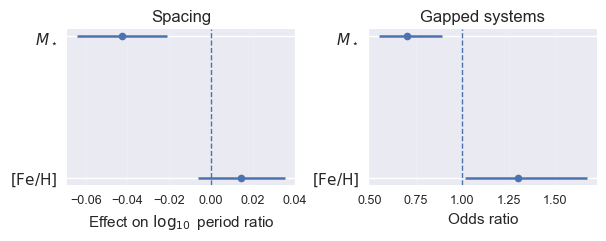

In [4]:
# ============================================================
# Outcome III poster figure
# Host-star effects on simple architecture metrics
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Frozen Outcome III results
# ------------------------------------------------------------

spacing = pd.DataFrame({
    "predictor": [r"$M_\star$", r"$[\mathrm{Fe/H}]$"],
    "coef": [-0.0426, 0.0147],
    "ci_low": [-0.0640, -0.0061],
    "ci_high": [-0.0212, 0.0355]
})

spacing["xerr_low"] = spacing["coef"] - spacing["ci_low"]
spacing["xerr_high"] = spacing["ci_high"] - spacing["coef"]

gapped = pd.DataFrame({
    "predictor": [r"$M_\star$", r"$[\mathrm{Fe/H}]$"],
    "or": [0.7027, 1.3035],
    "ci_low": [0.5525, 1.0169],
    "ci_high": [0.8936, 1.6708]
})

gapped["xerr_low"] = gapped["or"] - gapped["ci_low"]
gapped["xerr_high"] = gapped["ci_high"] - gapped["or"]

# Reverse for visual order
spacing_plot = spacing.iloc[::-1].copy()
gapped_plot = gapped.iloc[::-1].copy()

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 11,
})

fig, axes = plt.subplots(1, 2, figsize=(6.2, 2.55))

# ------------------------------------------------------------
# Panel A: spacing coefficients
# ------------------------------------------------------------

axes[0].errorbar(
    spacing_plot["coef"],
    spacing_plot["predictor"],
    xerr=[
        spacing_plot["xerr_low"],
        spacing_plot["xerr_high"]
    ],
    fmt="o",
    markersize=5.5,
    linewidth=1.8,
    capsize=3.5
)

axes[0].axvline(0, linestyle="--", linewidth=1.0)

axes[0].set_title("Spacing")
axes[0].set_xlabel(r"Effect on $\log_{10}$ period ratio")
axes[0].grid(axis="x", alpha=0.18)

axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# ------------------------------------------------------------
# Panel B: gapped odds ratios
# ------------------------------------------------------------

axes[1].errorbar(
    gapped_plot["or"],
    gapped_plot["predictor"],
    xerr=[
        gapped_plot["xerr_low"],
        gapped_plot["xerr_high"]
    ],
    fmt="o",
    markersize=5.5,
    linewidth=1.8,
    capsize=3.5
)

axes[1].axvline(1, linestyle="--", linewidth=1.0)

axes[1].set_title("Gapped systems")
axes[1].set_xlabel("Odds ratio")
axes[1].grid(axis="x", alpha=0.18)

axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    figures / "OutcomeIII_architecture_stellar_effects_poster.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "OutcomeIII_architecture_stellar_effects_poster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()